Saving rumah.jpg to rumah.jpg


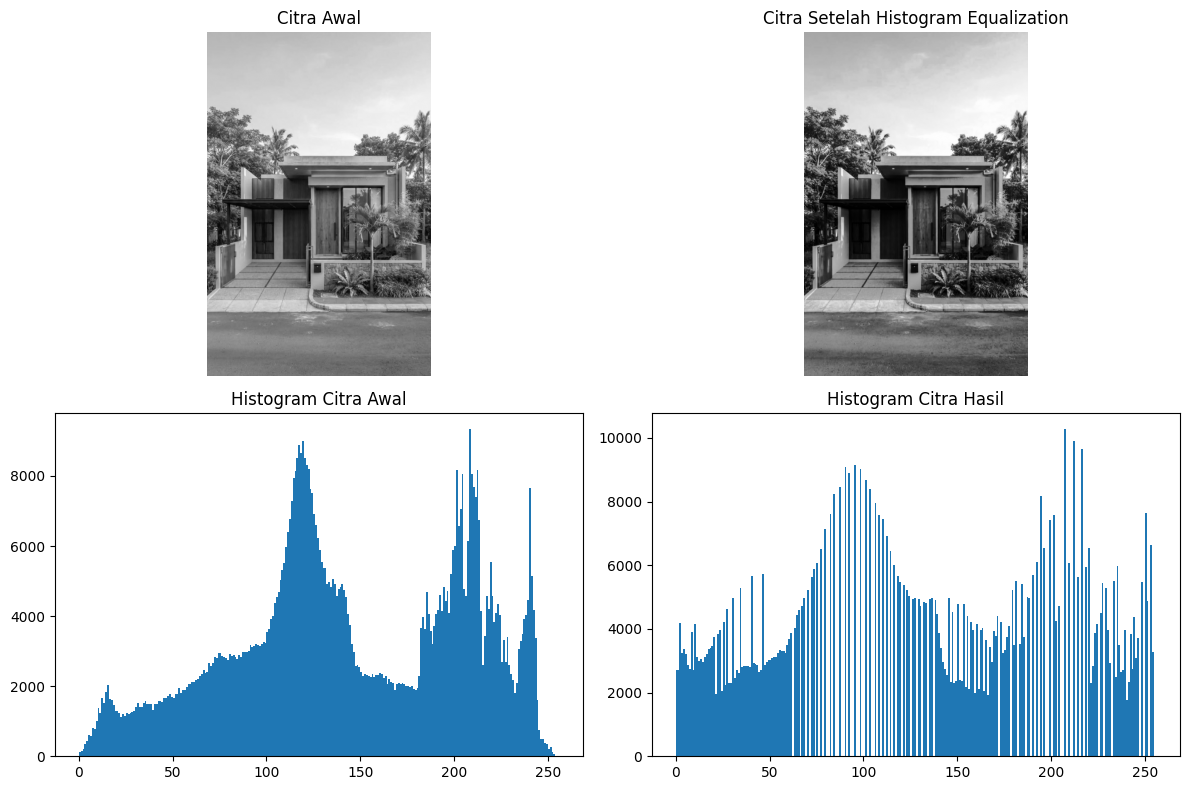

Proses peningkatan kualitas citra berhasil!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ==========================================
# PROJEK PENGOLAHAN CITRA DIGITAL
# Histogram Equalization
# ==========================================

import imageio.v3 as iio
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

from google.colab import files

# 1. Upload gambar
uploaded = files.upload()
nama_file = next(iter(uploaded))

# 2. Membaca gambar
img = iio.imread(nama_file)

# 3. Mengubah gambar menjadi grayscale
if img.ndim == 3:
    if img.shape[2] == 4:
        img = img[:, :, :3]

    gray = np.dot(
        img[:, :, :3],
        [0.299, 0.587, 0.114]
    ).astype(np.uint8)
else:
    gray = img.astype(np.uint8)

# 4. Mengurangi noise menggunakan Gaussian Filter
smooth = ndimage.gaussian_filter(
    gray.astype(float), sigma=0.5
)

smooth = np.clip(smooth, 0, 255).astype(np.uint8)

# 5. Menghitung histogram
histogram = np.bincount(
    smooth.ravel(), minlength=256
)

# 6. Menghitung Cumulative Distribution Function (CDF)
cdf = histogram.cumsum()

# 7. Melakukan Histogram Equalization
cdf_min = cdf[cdf > 0][0]

cdf_normalized = (
    (cdf - cdf_min) * 255 /
    (cdf[-1] - cdf_min)
)

cdf_normalized = np.clip(
    cdf_normalized, 0, 255
).astype(np.uint8)

# Membuat citra hasil
hasil = cdf_normalized[smooth]

# 8. Menampilkan hasil
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(hasil, cmap='gray')
plt.title('Citra Setelah Histogram Equalization')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title('Histogram Citra Awal')

plt.subplot(2, 2, 4)
plt.hist(hasil.ravel(), bins=256, range=(0, 256))
plt.title('Histogram Citra Hasil')

plt.tight_layout()
plt.show()

# 9. Menyimpan gambar hasil
iio.imwrite('hasil_equalization.png', hasil)

print("Proses peningkatan kualitas citra berhasil!")
files.download('hasil_equalization.png')
